# Tema 7

# Exercise 1 - Estimating Population size

M = 20 marked animals
On the second catch, from n = 15 animals, only Y = 4 were marked.
We want to find out how many animals are in total? (`N`)

We already have Y | N ~ Hypergeometric(N,M,n) and N ~ DiscreteUniform(20,200)

# a) The Model and the posterior distribution of N

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy import stats

In [13]:
M = 20
n = 15
Y_obs = 4

In [14]:
with pm.Model() as model:
    N = pm.DiscreteUniform("N", lower=20, upper=200)
    Y = pm.HyperGeometric("Y", N=N, k=M, n=n, observed = Y_obs)
    idata = pm.sample(draws=5000, tune=1000, chains=4, random_seed=42)

N_s = idata.posterior["N"].values.ravel()
print("numar de esantioane:", len(N_s))
az.summary(idata, ci_kind="hdi", ci_prob=0.95, round_to=2)

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [N]


Output()

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 11 seconds.


numar de esantioane: 20000


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
N,102.98,37.91,41.0,177.0,3927.66,4460.63,1.0,0.62,0.36


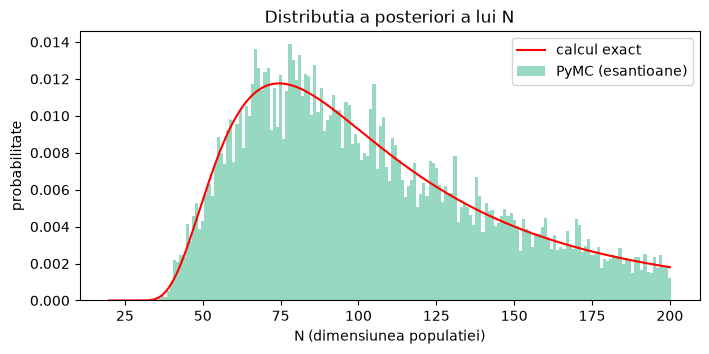

In [28]:
N_val = np.arange(20, 201)
post_exact = stats.hypergeom.pmf(Y_obs, N_val, M, n)
post_exact = post_exact / post_exact.sum()

frecv = np.bincount(N_s, minlength=201)[20:201] / len(N_s)
plt.figure(figsize=(8, 3.5))
plt.bar(N_val, frecv, width=1, color="#96D9C0", label="PyMC (esantioane)")
plt.plot(N_val, post_exact, color="#FF0000", label="calcul exact")
plt.xlabel("N (dimensiunea populatiei)"); plt.ylabel("probabilitate")
plt.title("Distributia a posteriori a lui N")
plt.legend()
plt.savefig("ex1_posterior_N.png", dpi=120, bbox_inches="tight")
plt.show()

# b) The mean, the median, the 95% HDI, and the classical estimate

In [22]:
media = N_s.mean()
mediana = np.median(N_s)
hdi = az.hdi(N_s, prob=0.95)
clasic = M * n / Y_obs

print(f"posterior mean = {media:.1f}")
print(f"posterior median = {mediana:.0f}")
print(f"HDI 95%              = [{hdi[0]:.0f}, {hdi[1]:.0f}]")
print(f"the classical estimate M*n/Y = {clasic:.0f}")

posterior mean = 103.0
posterior median = 96
HDI 95%              = [41, 177]
the classical estimate M*n/Y = 75


The classical estimate (75) is the peak of the posterior distribution. The posterior mean (103) is higher because the distribution is skewed, with a long tail stretching toward larger values. We only caught 4 marked animals, which is very few. With so little data, population sizes much larger than 75 remain plausible.

# c) P(N > 100 | Y =4)

In [24]:
p_peste_100 = (N_s > 100).mean()
print(f"P(N > 100 | Y = 4) ≈ {p_peste_100:.3f}")

P(N > 100 | Y = 4) ≈ 0.454


# d) Posterior predictive distribution for a new capture of 15 animals

For each N in the posterior, we simulate a new capture of 15 animals and count how many are marked.   

C:\Users\maria\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run hypergeometric_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [Y]


Output()

P(Y_nou =  0) ≈ 0.044
P(Y_nou =  1) ≈ 0.126
P(Y_nou =  2) ≈ 0.199
P(Y_nou =  3) ≈ 0.203
P(Y_nou =  4) ≈ 0.175
P(Y_nou =  5) ≈ 0.120
P(Y_nou =  6) ≈ 0.071
P(Y_nou =  7) ≈ 0.037
P(Y_nou =  8) ≈ 0.016
P(Y_nou =  9) ≈ 0.006
P(Y_nou = 10) ≈ 0.002


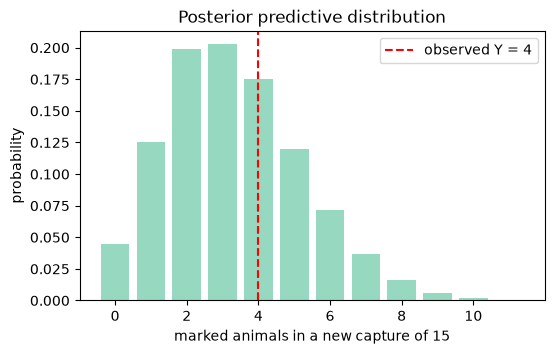

In [30]:
with model:
    pp = pm.sample_posterior_predictive(idata, random_seed=42)

Y_nou = pp.posterior_predictive["Y"].values.ravel()
frecv_Y = np.bincount(Y_nou) / len(Y_nou)
for y, p in enumerate(frecv_Y[:11]):
    print(f"P(Y_nou = {y:2d}) ≈ {p:.3f}")

plt.figure(figsize=(6, 3.5))
plt.bar(range(len(frecv_Y)), frecv_Y, color="#96D9C0")
plt.axvline(Y_obs, color="#FF0000", ls="--", label="observed Y = 4")
plt.xlabel("marked animals in a new capture of 15"); plt.ylabel("probability")
plt.title("Posterior predictive distribution")
plt.legend()
plt.savefig("ex1_predictiva_Y.png", dpi=120, bbox_inches="tight")
plt.show()

# Exercise 2 - The comparison of 2 treatments

A, B = Treatments |
λ - Rate |
Average Time = 1/λ |
λ A, λ B ~ Gamma(2,4)


In [31]:
A = np.array([3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9])
B = np.array([2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7])
print("A mean:", A.mean(), "| B mean:", B.mean())

A mean: 3.775 | B mean: 2.7875


In [32]:
# a) The Model

In [33]:
with pm.Model() as model:
    lam_A = pm.Gamma("lam_A", alpha=2, beta=4)
    lam_B = pm.Gamma("lam_B", alpha=2, beta=4)
    pm.Exponential("obs_A", lam=lam_A, observed=A)
    pm.Exponential("obs_B", lam=lam_B, observed=B)
    idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

az.summary(idata, ci_kind="hdi", ci_prob=0.95, round_to=2)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [lam_A, lam_B]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 9 seconds.


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
lam_A,0.29,0.09,0.13,0.48,7104.23,5149.06,1.0,0.0,0.0
lam_B,0.38,0.12,0.16,0.61,7876.24,5665.85,1.0,0.0,0.0


# b) Posterior distributions of the mean times and 95% HDI

Average Time A: 3.78 days, HDI 95% = [1.72, 6.40]
Average Time B: 2.93 days, HDI 95% = [1.33, 4.95]


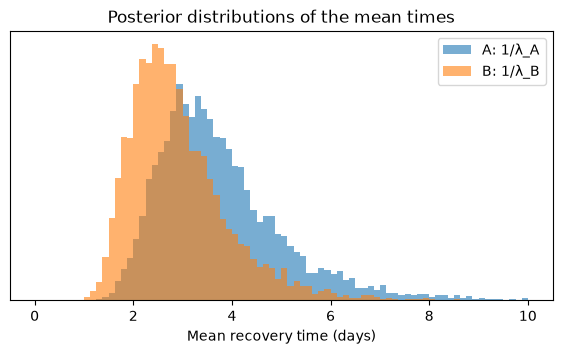

In [35]:
mA = 1 / idata.posterior["lam_A"].values.ravel()
mB = 1 / idata.posterior["lam_B"].values.ravel()
hdi_A = az.hdi(mA, prob=0.95)
hdi_B = az.hdi(mB, prob=0.95)
print(f"Average Time A: {mA.mean():.2f} days, HDI 95% = [{hdi_A[0]:.2f}, {hdi_A[1]:.2f}]")
print(f"Average Time B: {mB.mean():.2f} days, HDI 95% = [{hdi_B[0]:.2f}, {hdi_B[1]:.2f}]")

plt.figure(figsize=(7, 3.5))
plt.hist(mA, bins=80, range=(0, 10), alpha=0.6, density=True, label="A: 1/λ_A")
plt.hist(mB, bins=80, range=(0, 10), alpha=0.6, density=True, label="B: 1/λ_B")
plt.xlabel("Mean recovery time (days)"); plt.yticks([])
plt.title("Posterior distributions of the mean times")
plt.legend()
plt.savefig("ex2_timpi_medii.png", dpi=120, bbox_inches="tight")
plt.show()

# c) P(mean time B < mean time A)

In [37]:
p_c = (mB < mA).mean()
print(f"P(1/λ_B < 1/λ_A | date) ≈ {p_c:.3f}")

P(1/λ_B < 1/λ_A | date) ≈ 0.711


# d) Two new patients: probability that patient B recovers faster (or Two new patients: the probability of patient B recovering faster)

Sampling: [obs_A, obs_B]


Output()

P(New Patient B < New Patient A) ≈ 0.560
comparation: point c) ≈ 0.711


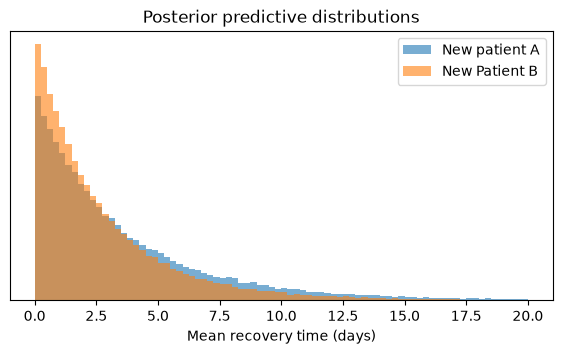

In [38]:
with model:
    pp = pm.sample_posterior_predictive(idata, random_seed=42)

pacient_A = pp.posterior_predictive["obs_A"].values.ravel()
pacient_B = pp.posterior_predictive["obs_B"].values.ravel()

p_d = (pacient_B < pacient_A).mean()
print(f"P(New Patient B < New Patient A) ≈ {p_d:.3f}")
print(f"comparation: point c) ≈ {p_c:.3f}")

plt.figure(figsize=(7, 3.5))
plt.hist(pacient_A, bins=80, range=(0, 20), alpha=0.6, density=True, label="New patient A")
plt.hist(pacient_B, bins=80, range=(0, 20), alpha=0.6, density=True, label="New Patient B")
plt.xlabel("Mean recovery time (days)"); plt.yticks([])
plt.title("Posterior predictive distributions")
plt.legend()
plt.savefig("ex2_predictiva.png", dpi=120, bbox_inches="tight")
plt.show()

Why they differ. In c), we’re comparing the treatment means; the uncertainty only comes from not knowing lambda(A) and lambda(B) exactly. In d), we’re comparing two individual patients. Recovery times vary a lot from one patient to another (the exponential distribution has wide spread), so a patient B can easily take longer to recover than a patient A, even if B is better on average. That’s why the probability drops close to 0.5.

# Exercise 3 — Detecting a gradual rate change

* λ1 = initial rate, λ2 - final rate
* τ = midpoint day of the transition
* k = how fast is the change

In [40]:
y = np.array([3, 4, 2, 5, 3, 4, 3, 2, 4, 3, 4, 5, 5, 6, 5, 7, 6, 8, 7, 9,
              8, 10, 9, 8, 11, 9, 10, 8, 9, 10])
t = np.arange(1, 31)

In [ ]:
# a) Model

In [42]:
with pm.Model() as model:
    lam1 = pm.Exponential("lam1", lam=0.2)
    lam2 = pm.Exponential("lam2", lam=0.2)
    tau = pm.Uniform("tau", lower=1, upper=30)
    k = pm.Exponential("k", lam=1)

    lam_t = lam1 + (lam2 - lam1) / (1 + pm.math.exp(-k * (t - tau)))
    pm.Poisson("Y", mu=lam_t, observed=y)

    idata = pm.sample(draws=2000, tune=2000, chains=4, target_accept=0.95, random_seed=42)

az.summary(idata, var_names=["lam1", "lam2", "tau", "k"], ci_kind="hdi", ci_prob=0.95, round_to=2)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [lam1, lam2, tau, k]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 12 seconds.


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
lam1,2.88,1.06,0.50,4.64,1908.17,1421.44,1.0,0.03,0.02
lam2,9.90,2.12,6.87,14.47,1497.18,1181.87,1.0,0.07,0.10
tau,16.03,3.64,8.90,24.39,1910.57,1232.70,1.0,0.09,0.13
k,0.58,0.65,0.05,1.86,1322.99,1552.33,1.0,0.01,0.02


# b) Posterior distributions of τ and k

tau: mean = 16.03, HDI 95% = [8.90, 24.39]
k:   mean = 0.58, HDI 95% = [0.05, 1.86]


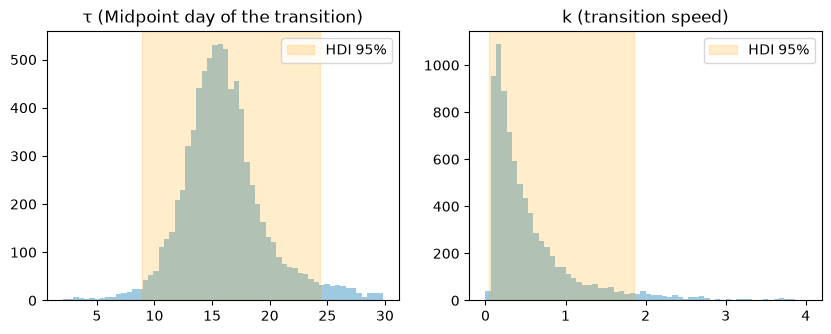

In [44]:
tau_s = idata.posterior["tau"].values.ravel()
k_s = idata.posterior["k"].values.ravel()
hdi_tau = az.hdi(tau_s, prob=0.95)
hdi_k = az.hdi(k_s, prob=0.95)
print(f"tau: mean = {tau_s.mean():.2f}, HDI 95% = [{hdi_tau[0]:.2f}, {hdi_tau[1]:.2f}]")
print(f"k:   mean = {k_s.mean():.2f}, HDI 95% = [{hdi_k[0]:.2f}, {hdi_k[1]:.2f}]")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(tau_s, bins=60, color="#9ecae1")
ax[0].axvspan(hdi_tau[0], hdi_tau[1], color="orange", alpha=0.2, label="HDI 95%")
ax[0].set_title("τ (Midpoint day of the transition)"); ax[0].legend()
ax[1].hist(k_s, bins=60, range=(0, 4), color="#9ecae1")
ax[1].axvspan(hdi_k[0], hdi_k[1], color="orange", alpha=0.2, label="HDI 95%")
ax[1].set_title("k (transition speed)"); ax[1].legend()
plt.savefig("ex3_tau_k.png", dpi=120, bbox_inches="tight")
plt.show()

# c) P(λ2 > λ1 | date) and the estimated evolution of λt

P(λ2 > λ1 | date) ≈ 1.000


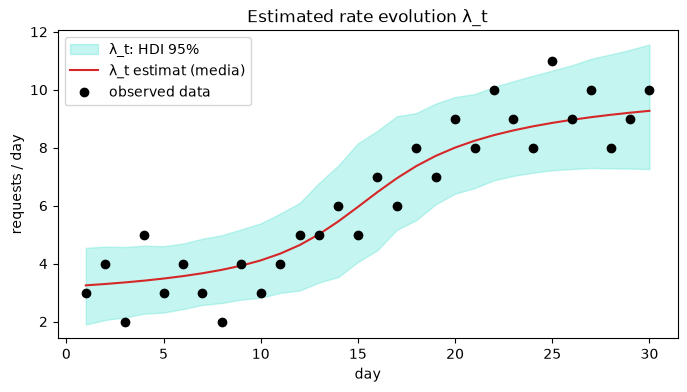

In [46]:
lam1_s = idata.posterior["lam1"].values.ravel()
lam2_s = idata.posterior["lam2"].values.ravel()
print(f"P(λ2 > λ1 | date) ≈ {(lam2_s > lam1_s).mean():.3f}")

lam_t_s = lam1_s[:, None] + (lam2_s - lam1_s)[:, None] / (1 + np.exp(-k_s[:, None] * (t - tau_s[:, None])))
lam_t_medie = lam_t_s.mean(axis=0)
lam_t_hdi = np.array([az.hdi(lam_t_s[:, i], prob=0.95) for i in range(30)])

plt.figure(figsize=(8, 4))
plt.fill_between(t, lam_t_hdi[:, 0], lam_t_hdi[:, 1], color="turquoise", alpha=0.3, label="λ_t: HDI 95%")
plt.plot(t, lam_t_medie, color="#d62728", label="λ_t estimat (media)")
plt.plot(t, y, "o", color="black", label="observed data")
plt.xlabel("day"); plt.ylabel("requests / day")
plt.title("Estimated rate evolution λ_t")
plt.legend()
plt.savefig("ex3_lambda_t.png", dpi=120, bbox_inches="tight")
plt.show()

# d) Posterior predictive distribution over the 30 days

Sampling: [Y]


Output()

Days with observed value within the 95% predictive interval: 100%


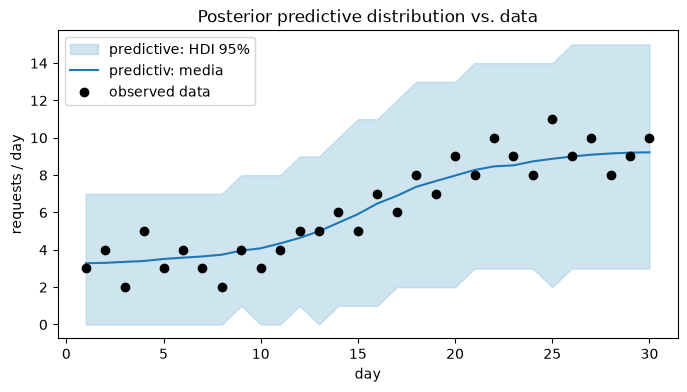

In [47]:
with model:
    pp = pm.sample_posterior_predictive(idata, random_seed=42)

Y_sim = pp.posterior_predictive["Y"].values.reshape(-1, 30)
Y_hdi = np.array([az.hdi(Y_sim[:, i], prob=0.95) for i in range(30)])
in_interval = ((y >= Y_hdi[:, 0]) & (y <= Y_hdi[:, 1])).mean()
print(f"Days with observed value within the 95% predictive interval: {in_interval * 100:.0f}%")

plt.figure(figsize=(8, 4))
plt.fill_between(t, Y_hdi[:, 0], Y_hdi[:, 1], color="#9ecae1", alpha=0.5, label="predictive: HDI 95%")
plt.plot(t, Y_sim.mean(axis=0), color="#1f77b4", label="predictiv: media")
plt.plot(t, y, "o", color="black", label="observed data")
plt.xlabel("day"); plt.ylabel("requests / day")
plt.title("Posterior predictive distribution vs. data")
plt.legend()
plt.savefig("ex3_predictiva.png", dpi=120, bbox_inches="tight")
plt.show()